# Ejercicio 9. Verificación de una mezcla que termina antes de tiempo

Este cuaderno acompaña al informe [`ejercicio-09.md`](ejercicio-09.md).
Ejecuta el mismo código, mide comparaciones, verifica el adversario y genera
`ejercicio-09.png`. Las secciones siguen la numeración del informe.

La variante hace como máximo $2n-2$ comparaciones para $n\ge1$, pero una mezcla
correcta necesita $2n-1$ en el peor caso. **La cota decide la incorrectitud antes
de ejecutar pruebas.** El experimento posterior comprueba las predicciones y
el contraejemplo construido mediante el adversario.

Se cuenta una comparación por consulta $x\le y$. Los oráculos y las aserciones
quedan fuera del costo analizado. Para reproducirlo hacen falta Python 3,
`matplotlib` e `IPython`.


In [1]:
from collections import Counter
from itertools import combinations, combinations_with_replacement
from math import comb
from random import Random

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import Image, display


## 1. Formulación y modelo

Las entradas tienen el mismo largo $n\ge0$ y están ordenadas de forma no
decreciente. La salida debe conservar todas las apariciones y estar ordenada.
Se permiten repetidos. El oráculo usa `sorted` y las pruebas usan `Counter`;
estas herramientas no pertenecen al algoritmo ni al conteo de comparaciones.


In [2]:
def reference_merge(A, B):
    return sorted(list(A) + list(B))


def is_sorted(A):
    return all(A[k] <= A[k + 1] for k in range(len(A) - 1))


class CountingLeq:
    def __init__(self):
        self.calls = []

    def __call__(self, x, y):
        answer = x <= y
        self.calls.append((x, y, answer))
        return answer


assert reference_merge([], []) == []
assert reference_merge([1, 3, 4], [0, 2, 5]) == list(range(6))


## 2. La variante y su peor caso exacto

El ciclo termina cuando $i=n-1$ o $j=n$. Como cada consulta incrementa un índice,
el número de comparaciones es $i+j$. Si termina por $i=n-1$, entonces
$j\le n-1$; si termina por $j=n$, entonces $i\le n-2$. En ambos casos son
a lo sumo $2n-2$ comparaciones. Para $n=1$ son cero y la fórmula sigue valiendo;
para $n=0$ también son cero, pero se trata aparte.

Al salir, se copia primero el sufijo de $B$ y después el de $A$. El código
siguiente es idéntico al del informe.


In [3]:
def leq(x, y):
    return x <= y


def merge_shortcut(A, B, leq=leq):
    n = len(A)
    if len(B) != n:
        raise ValueError("se requieren dos listas del mismo largo")
    result = []
    i, j = 0, 0
    while i < n - 1 and j < n:
        if leq(A[i], B[j]):
            result.append(A[i])
            i += 1
        else:
            result.append(B[j])
            j += 1
    for k in range(j, n):
        result.append(B[k])
    for k in range(i, n):
        result.append(A[k])
    return result


## 3. Decisión sin pruebas: contradicción con la cota mínima

La conferencia 5, sección 6, prueba que una mezcla correcta necesita $2n-1$
comparaciones en el peor caso. En la cadena

$$b_1<a_1<b_2<a_2<\cdots<b_n<a_n$$

hay $2n-1$ pares de vecinos de listas distintas. Cada par debe compararse
directamente: intercambiar sus valores conserva el orden de cada lista y todas
las demás relaciones, pero cambia su orden correcto en la salida.

Si la variante fuera correcta, su peor caso sería simultáneamente al menos
$2n-1$ y a lo sumo $2n-2$. Es imposible. Esta es la decisión solicitada
**sin probar la implementación**. A continuación se construye el fallo que
predice la demostración y luego se contrasta con el código.


## 4. El adversario construye el fallo y señala la reparación

La variante hace $2n-2$ consultas sobre la intercalación inversa anterior y deja
sin comparar $a_n,b_n$. En esa entrada, copiar $b_n,a_n$ acierta. Si se
intercambian sus valores, las consultas a posiciones y sus respuestas permanecen
iguales, pero copiar $b_n,a_n$ falla. Para $n=3$, las entradas son
$A=[1,3,5],B=[0,2,4]$ y $A=[1,3,4],B=[0,2,5]$.

### Reparación

La mezcla habitual compara mientras **ambas** listas tengan elementos.
El invariante dice que la salida contiene las posiciones ya consumidas, está
ordenada y todo lo emitido es menor o igual que todo lo pendiente. Al agotarse
una lista, copiar el otro sufijo es correcto. El potencial $2n-i-j$ disminuye
por comparación; antes de comparar quedan al menos dos elementos, de donde
se obtiene la cota superior $2n-1$. La intercalación perfecta la alcanza.


In [4]:
def merge_standard(A, B, leq=leq):
    n = len(A)
    if len(B) != n:
        raise ValueError("se requieren dos listas del mismo largo")
    result = []
    i, j = 0, 0
    while i < n and j < n:
        if leq(A[i], B[j]):
            result.append(A[i])
            i += 1
        else:
            result.append(B[j])
            j += 1
    for k in range(j, n):
        result.append(B[k])
    for k in range(i, n):
        result.append(A[k])
    return result


### Vigilancia del prefijo y del conteo

La siguiente versión guarda las consultas y verifica el invariante antes y
después de cada comparación de ambos ciclos. La variante conserva ese invariante
durante el ciclo, pero puede copiar dos sufijos que aún requieren comparación.
El conteo de esta versión se contrasta con el comparador del código real.


In [5]:
def watched_merge(A, B, shortcut):
    n = len(A)
    i, j, result, trace = 0, 0, [], []

    def invariant():
        assert 0 <= i <= n and 0 <= j <= n
        assert len(result) == i + j
        assert Counter(result) == Counter(list(A[:i]) + list(B[:j]))
        assert is_sorted(result)
        remaining = list(A[i:]) + list(B[j:])
        if result and remaining:
            assert max(result) <= min(remaining)

    invariant()
    limit = n - 1 if shortcut else n
    while i < limit and j < n:
        old_i, old_j = i, j
        before = 2 * n - i - j
        a, b = A[i], B[j]
        answer = a <= b
        if answer:
            result.append(a)
            i += 1
        else:
            result.append(b)
            j += 1
        after = 2 * n - i - j
        assert 0 <= after == before - 1
        trace.append(dict(i=old_i, j=old_j, a=a, b=b, answer=answer,
                          emitted=result[-1], next_i=i, next_j=j,
                          before=before, after=after))
        invariant()
    stop = i, j
    assert len(trace) == i + j
    result.extend(B[j:])
    result.extend(A[i:])
    assert len(result) == 2 * n
    assert Counter(result) == Counter(list(A) + list(B))
    return result, trace, stop


def verify_case(A, B):
    n = len(A)
    assert len(B) == n and is_sorted(A) and is_sorted(B)
    snapshot = tuple(map(id, A)), tuple(map(id, B))
    counts = []
    expected = reference_merge(A, B)
    for shortcut, algorithm in [(True, merge_shortcut), (False, merge_standard)]:
        counter = CountingLeq()
        actual = algorithm(A, B, leq=counter)
        watched, trace, stop = watched_merge(A, B, shortcut)
        assert actual == watched
        assert counter.calls == [(r['a'], r['b'], r['answer']) for r in trace]
        assert Counter(actual) == Counter(expected) and len(actual) == 2 * n
        bound = max(0, 2 * n - (2 if shortcut else 1))
        assert len(counter.calls) <= bound
        if shortcut:
            assert (actual == expected) == (n == 0 or B[-1] <= A[-1])
        else:
            assert actual == expected
        counts.append(len(counter.calls))
    assert snapshot == (tuple(map(id, A)), tuple(map(id, B)))
    return tuple(counts)


example_A, example_B = [1, 3, 4], [0, 2, 5]
assert verify_case(example_A, example_B) == (4, 5)
example_output, example_trace, example_stop = watched_merge(example_A, example_B, True)
assert example_output == [0, 1, 2, 3, 5, 4]
assert example_stop == (2, 2)
assert [(r['i'], r['j'], r['answer'], r['emitted'], r['next_i'], r['next_j'])
        for r in example_trace] == [
    (0, 0, False, 0, 0, 1), (0, 1, True, 1, 1, 1),
    (1, 1, False, 2, 1, 2), (1, 2, True, 3, 2, 2),
]
print('Tabla 1. Traza del contraejemplo con n=3')
print('vuelta   i j   comparación   respuesta   emitido   nuevo i j')
for k, r in enumerate(example_trace, 1):
    print(f'{k:6} {r["i"]:3} {r["j"]}   {r["a"]} <= {r["b"]} '
          f'      {str(r["answer"]):5} {r["emitted"]:9} {r["next_i"]:7} {r["next_j"]}')
print('Copia sin comparar: B[2]=5, A[2]=4')
print('Salida:', example_output)
print('Salida correcta:', merge_standard(example_A, example_B))


Tabla 1. Traza del contraejemplo con n=3
vuelta   i j   comparación   respuesta   emitido   nuevo i j
     1   0 0   1 <= 0       False         0       0 1
     2   0 1   1 <= 2       True          1       1 1
     3   1 1   3 <= 2       False         2       1 2
     4   1 2   3 <= 5       True          3       2 2
Copia sin comparar: B[2]=5, A[2]=4
Salida: [0, 1, 2, 3, 5, 4]
Salida correcta: [0, 1, 2, 3, 4, 5]


### Las dos entradas indistinguibles, con claves etiquetadas

Las claves siguientes tienen un rango y una posición de entrada. Las etiquetas
se conservan al intercambiar **rangos** de las dos últimas posiciones. Se comparan
las listas de consultas mediante etiquetas y respuestas, no mediante valores:
los valores cambian, pero sus relaciones con los demás no.

Para cada $1\le n\le128$ se verifica que ambas entradas están ordenadas, que
el atajo consulta los mismos pares de posiciones y obtiene las mismas respuestas,
que su salida tiene las mismas etiquetas y que solo en la segunda entrada
invierte los dos mayores. La mezcla reparada distingue el último par y acierta
en ambas, con $2n-1$ comparaciones.


In [6]:
class Key:
    def __init__(self, rank, label):
        self.rank, self.label = rank, label

    def __le__(self, other):
        return self.rank <= other.rank

    def __repr__(self):
        return f'{self.label}:{self.rank}'


def adversary_inputs(n, swap_last=False):
    A = [Key(2 * k + 1, ('A', k)) for k in range(n)]
    B = [Key(2 * k, ('B', k)) for k in range(n)]
    if swap_last and n:
        A[-1].rank, B[-1].rank = B[-1].rank, A[-1].rank
    return A, B


def signature(calls):
    return [(a.label, b.label, answer) for a, b, answer in calls]


family_records = [dict(n=0, shortcut=0, standard=0, lower=0)]
for n in range(1, 129):
    original_A, original_B = adversary_inputs(n)
    swapped_A, swapped_B = adversary_inputs(n, swap_last=True)
    for A, B in [(original_A, original_B), (swapped_A, swapped_B)]:
        assert is_sorted(A) and is_sorted(B)
        assert sorted(x.rank for x in A + B) == list(range(2 * n))
    before_counter, after_counter = CountingLeq(), CountingLeq()
    before_output = merge_shortcut(original_A, original_B, leq=before_counter)
    after_output = merge_shortcut(swapped_A, swapped_B, leq=after_counter)
    assert signature(before_counter.calls) == signature(after_counter.calls)
    assert len(before_counter.calls) == len(after_counter.calls) == 2 * n - 2
    assert [x.label for x in before_output] == [x.label for x in after_output]
    assert [x.rank for x in before_output] == list(range(2 * n))
    assert [x.rank for x in after_output] == list(range(2 * n - 2)) + [2 * n - 1, 2 * n - 2]
    last_pair = {('A', n - 1), ('B', n - 1)}
    assert all({a.label, b.label} != last_pair for a, b, answer in after_counter.calls)
    for A, B in [(original_A, original_B), (swapped_A, swapped_B)]:
        counter = CountingLeq()
        output = merge_standard(A, B, leq=counter)
        assert [x.rank for x in output] == list(range(2 * n))
        assert len(counter.calls) == 2 * n - 1
        assert {counter.calls[-1][0].label, counter.calls[-1][1].label} == last_pair
    family_records.append(dict(n=n, shortcut=2*n-2, standard=2*n-1, lower=2*n-1))

assert merge_shortcut([0], [1]) == [1, 0]
assert merge_shortcut([], []) == []
print('ok: 128 pares de entradas indistinguibles y 128 fallos construidos')
print('Contraejemplo mínimo: A=[0], B=[1], salida=[1,0], cero comparaciones')
print('Tabla 2. Peor conteo medido en las familias y cota mínima')
print('  n   variante   reparada   cota mínima')
for n in [0, 1, 2, 3, 4, 8, 16, 32, 64]:
    r = family_records[n]
    print(f'{n:3} {r["shortcut"]:10} {r["standard"]:10} {r["lower"]:13}')


ok: 128 pares de entradas indistinguibles y 128 fallos construidos
Contraejemplo mínimo: A=[0], B=[1], salida=[1,0], cero comparaciones
Tabla 2. Peor conteo medido en las familias y cota mínima
  n   variante   reparada   cota mínima
  0          0          0             0
  1          0          1             1
  2          2          3             3
  3          4          5             5
  4          6          7             7
  8         14         15            15
 16         30         31            31
 32         62         63            63
 64        126        127           127


## 5. Verificación numérica

Se enumeran todas las intercalaciones de claves distintas para cada largo entre
0 y 8: se eligen los $n$ rangos que recibe $A$ y se asignan los restantes a $B$.
Esto cubre todos los órdenes conjuntos posibles. Se miden los máximos de ambos
algoritmos y se comprueba que, para $n\ge1$, exactamente la mitad de las entradas
hace fallar la variante, las que tienen su máximo en $B$.

Después se enumeran todos los pares de listas no decrecientes de largos 0 a 8
sobre tres símbolos, para cubrir repetidos. Cada caso verifica el invariante del
prefijo, el potencial, las consultas del código real, la conservación de las
entradas y la condición exacta de acierto $B[-1]\le A[-1]$.


In [7]:
interleaving_cases = 0
interleaving_records = []
for n in range(9):
    cases, failures, max_shortcut, max_standard = 0, 0, 0, 0
    for a_ranks in combinations(range(2 * n), n):
        selected = set(a_ranks)
        A = list(a_ranks)
        B = [rank for rank in range(2 * n) if rank not in selected]
        short_count, standard_count = verify_case(A, B)
        cases += 1
        failures += merge_shortcut(A, B) != reference_merge(A, B)
        max_shortcut = max(max_shortcut, short_count)
        max_standard = max(max_standard, standard_count)
    assert cases == comb(2 * n, n)
    assert failures == (cases // 2 if n else 0)
    assert max_shortcut == max(0, 2 * n - 2)
    assert max_standard == max(0, 2 * n - 1)
    interleaving_records.append((n, cases, failures, max_shortcut, max_standard))
    interleaving_cases += cases
assert interleaving_cases == 17577
print('Intercalaciones exhaustivas con claves distintas')
print(' n   casos   fallos del atajo   máximo atajo   máximo reparada')
for n, cases, failures, max_shortcut, max_standard in interleaving_records:
    print(f'{n:2} {cases:7} {failures:17} {max_shortcut:14} {max_standard:17}')
print(f'ok: {interleaving_cases} intercalaciones; los máximos coinciden con las fórmulas')

repeated_cases = 0
for n in range(9):
    arrays = list(combinations_with_replacement(range(3), n))
    for A in arrays:
        for B in arrays:
            verify_case(A, B)
            repeated_cases += 1
assert repeated_cases == 4917
print(f'ok: {repeated_cases} pares exhaustivos con repetidos, incluida la entrada vacía')


Intercalaciones exhaustivas con claves distintas
 n   casos   fallos del atajo   máximo atajo   máximo reparada
 0       1                 0              0                 0
 1       2                 1              0                 1
 2       6                 3              2                 3
 3      20                10              4                 5
 4      70                35              6                 7
 5     252               126              8                 9
 6     924               462             10                11
 7    3432              1716             12                13
 8   12870              6435             14                15
ok: 17577 intercalaciones; los máximos coinciden con las fórmulas
ok: 4917 pares exhaustivos con repetidos, incluida la entrada vacía


### Casos adicionales reproducibles y contrato de largos

Se prueban 100 pares por cada largo de la lista siguiente con semilla 2026,
incluyendo tamaños mayores y valores repetidos. Se comprueba también que
los largos distintos se rechazan. Estos casos complementan la enumeración;
la demostración es la que establece las cotas para cualquier largo.


In [8]:
rng = Random(2026)
random_cases = 0
for n in [1, 2, 3, 4, 8, 16, 32, 64, 128]:
    for _ in range(100):
        A = sorted(rng.choices(range(-2 * n, 2 * n + 1), k=n))
        B = sorted(rng.choices(range(-2 * n, 2 * n + 1), k=n))
        verify_case(A, B)
        random_cases += 1
assert random_cases == 900
print(f'ok: {random_cases} pares adicionales con semilla 2026')

invalid_cases = [([], [1]), ([1], []), ([1], [1, 2]), ([1, 2], [1])]
for algorithm in [merge_shortcut, merge_standard]:
    for A, B in invalid_cases:
        try:
            algorithm(A, B)
        except ValueError:
            pass
        else:
            raise AssertionError('debió rechazarse un largo distinto')
print('ok: las dos funciones rechazan los cuatro pares de largos inválidos')


ok: 900 pares adicionales con semilla 2026
ok: las dos funciones rechazan los cuatro pares de largos inválidos


## Figura 1

Las entradas del adversario para $n=3$ producen las mismas respuestas a consultas
de posiciones. Cambiar los valores de las dos últimas posiciones hace que el
atajo invierta los dos mayores. El gráfico de costos muestra que su peor caso
está exactamente una comparación por debajo de la cota mínima, que alcanza
la mezcla reparada. Que los órdenes asintóticos coincidan no salva la variante:
la contradicción usa las cotas exactas.


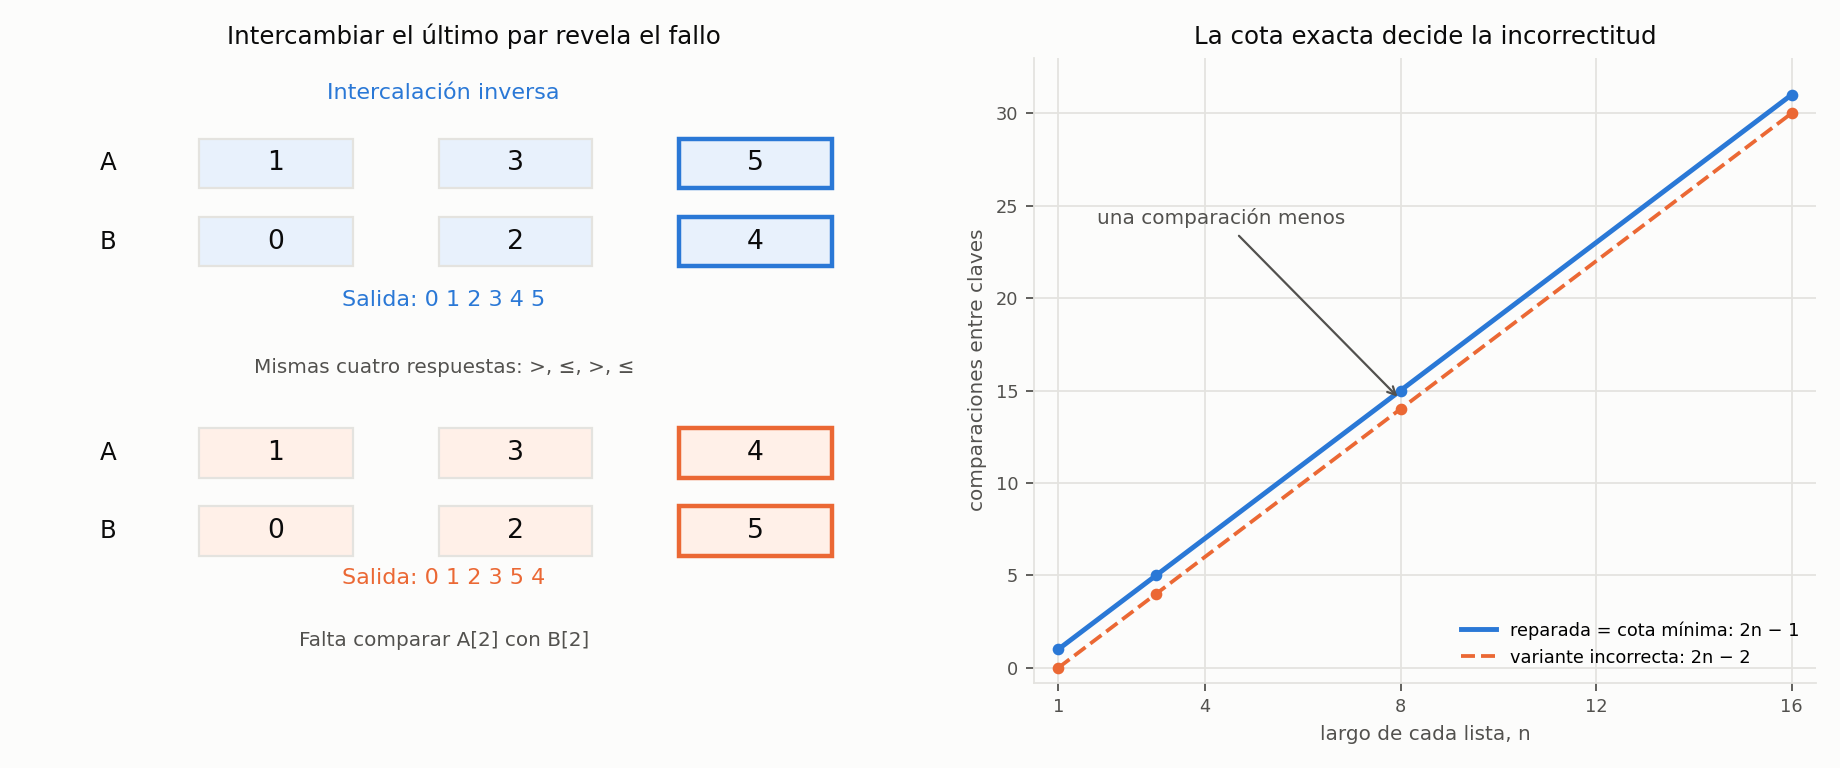

In [9]:
blue, orange = '#2a78d6', '#eb6834'
ink, secondary = '#0b0b0b', '#52514e'
grid, background = '#e4e3df', '#fcfcfb'
fig, (ax_pair, ax_cost) = plt.subplots(1, 2, figsize=(11.5, 4.8), dpi=160,
                                         gridspec_kw={'width_ratios': [1.15, 1]})
fig.patch.set_facecolor(background)

rows = [('A', [1, 3, 5], 3.6, blue), ('B', [0, 2, 4], 2.75, blue),
        ('A', [1, 3, 4], .45, orange), ('B', [0, 2, 5], -.4, orange)]
for label, values, y, color in rows:
    ax_pair.text(-.7, y, label, va='center', ha='center', color=ink, fontsize=11)
    for k, value in enumerate(values):
        highlight = k == 2
        ax_pair.add_patch(Rectangle((k - .32, y - .27), .64, .54,
                                    facecolor='#e8f1fc' if color == blue else '#fff0e8',
                                    edgecolor=color if highlight else grid,
                                    lw=2 if highlight else 1))
        ax_pair.text(k, y, str(value), ha='center', va='center', color=ink, fontsize=12)
ax_pair.text(.7, 4.3, 'Intercalación inversa', color=blue, ha='center', fontsize=10)
ax_pair.text(.7, 2.05, 'Salida: 0 1 2 3 4 5', color=blue, ha='center', fontsize=10)
ax_pair.text(.7, 1.32, 'Mismas cuatro respuestas: >, ≤, >, ≤',
              color=secondary, ha='center', fontsize=9)
ax_pair.text(.7, -.98, 'Salida: 0 1 2 3 5 4', color=orange, ha='center', fontsize=10)
ax_pair.text(.7, -1.65, 'Falta comparar A[2] con B[2]',
              color=secondary, ha='center', fontsize=9)
ax_pair.set_title('Intercambiar el último par revela el fallo', color=ink, fontsize=11)
ax_pair.set_xlim(-1.05, 2.7)
ax_pair.set_ylim(-2.05, 4.75)
ax_pair.axis('off')

ns = list(range(1, 17))
short_counts = [family_records[n]['shortcut'] for n in ns]
standard_counts = [family_records[n]['standard'] for n in ns]
ax_cost.plot(ns, standard_counts, color=blue, lw=2.2,
             label='reparada = cota mínima: 2n − 1')
ax_cost.plot(ns, short_counts, color=orange, lw=1.7, ls='--',
             label='variante incorrecta: 2n − 2')
ax_cost.scatter([1, 3, 8, 16], [family_records[n]['standard'] for n in [1, 3, 8, 16]],
                color=blue, s=18, zorder=3)
ax_cost.scatter([1, 3, 8, 16], [family_records[n]['shortcut'] for n in [1, 3, 8, 16]],
                color=orange, s=18, zorder=3)
ax_cost.annotate('una comparación menos', xy=(8, 14.5), xytext=(1.8, 24),
                 color=secondary, fontsize=9,
                 arrowprops=dict(arrowstyle='->', color=secondary))
ax_cost.set_title('La cota exacta decide la incorrectitud', color=ink, fontsize=11)
ax_cost.set_xlabel('largo de cada lista, n', color=secondary, fontsize=9)
ax_cost.set_ylabel('comparaciones entre claves', color=secondary, fontsize=9)
ax_cost.set_xlim(.5, 16.5)
ax_cost.set_ylim(-.8, 33)
ax_cost.set_xticks([1, 4, 8, 12, 16])
ax_cost.set_facecolor(background)
ax_cost.grid(color=grid, lw=.8)
for side in ['top', 'right']:
    ax_cost.spines[side].set_visible(False)
for side in ['left', 'bottom']:
    ax_cost.spines[side].set_color(grid)
ax_cost.tick_params(colors=secondary, labelsize=8)
ax_cost.legend(frameon=False, fontsize=8, loc='lower right')
fig.tight_layout(w_pad=2)
fig.savefig('ejercicio-09.png', facecolor=background)
plt.close(fig)
display(Image(filename='ejercicio-09.png'))


## 6. Conclusiones

La variante hace como máximo $2n-2$ comparaciones para $n\ge1$, en contradicción
con las $2n-1$ que necesita una mezcla correcta. El adversario transforma esa
contradicción en una entrada concreta: intercambia los valores de las dos
últimas posiciones, que no fueron comparadas. La variante mantiene las mismas
consultas y respuestas, pero termina invirtiendo los dos mayores.

La mezcla reparada compara mientras ambas listas tengan elementos, es correcta
por su invariante y alcanza la cota mínima. Las pruebas comprueban los casos
enumerados y la implementación; las demostraciones cubren cualquier largo.


In [10]:
print('Todas las comprobaciones finalizaron correctamente.')
print(f'Intercalaciones exhaustivas: {interleaving_cases}')
print(f'Pares exhaustivos con repetidos: {repeated_cases}')
print(f'Pares adicionales reproducibles: {random_cases}')
print('Familias del adversario: largos 1 a 128, con y sin intercambio final')
print('Peor caso: variante 2n-2; mezcla correcta 2n-1, para n>=1')
print('Figura guardada en ejercicio-09.png')


Todas las comprobaciones finalizaron correctamente.
Intercalaciones exhaustivas: 17577
Pares exhaustivos con repetidos: 4917
Pares adicionales reproducibles: 900
Familias del adversario: largos 1 a 128, con y sin intercambio final
Peor caso: variante 2n-2; mezcla correcta 2n-1, para n>=1
Figura guardada en ejercicio-09.png
